In [1]:
import time

import numpy as np
import pandas as pd
import requests

df = pd.read_csv('data/qualifying_raw.csv')
df

,year,round,circuit,circuitType,date,position,driverNumber,driverId,constructorId,engineManufacturerId,tyreManufacturerId,q1,q2,q3,gap,interval,laps,dateOfBirth
0,2014,1,melbourne,STREET,2014-03-16,1,44,lewis-hamilton,mercedes,mercedes,pirelli,1:31.699,1:42.890,1:44.231,NaN,NaN,22.0,1985-01-07
1,2014,1,melbourne,STREET,2014-03-16,2,3,daniel-ricciardo,red-bull,renault,pirelli,1:30.775,1:42.295,1:44.548,0.317,0.317,20.0,1989-07-01
2,2014,1,melbourne,STREET,2014-03-16,3,6,nico-rosberg,mercedes,mercedes,pirelli,1:32.564,1:42.264,1:44.595,0.364,0.047,21.0,1985-06-27
3,2014,1,melbourne,STREET,2014-03-16,4,20,kevin-magnussen,mclaren,mercedes,pirelli,1:30.949,1:43.247,1:45.745,1.514,1.150,19.0,1992-10-05
4,2014,1,melbourne,STREET,2014-03-16,5,14,fernando-alonso,ferrari,ferrari,pirelli,1:31.388,1:42.805,1:45.819,1.588,0.074,21.0,1981-07-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5460,2026,17,marina-bay,STREET,2026-10-11,18,23,alexander-albon,williams,mercedes,pirelli,1:34.289,NaN,NaN,NaN,NaN,10.0,1996-03-23
5461,2026,17,marina-bay,STREET,2026-10-11,19,18,lance-stroll,aston-martin,honda,pirelli,1:34.946,NaN,NaN,NaN,NaN,8.0,1998-10-29
5462,2026,17,marina-bay,STREET,2026-10-11,20,11,sergio-perez,cadillac,ferrari,pirelli,1:35.123,NaN,NaN,NaN,NaN,8.0,1990-01-26
5463,2026,17,marina-bay,STREET,2026-10-11,21,77,valtteri-bottas,cadillac,ferrari,pirelli,1:35.984,NaN,NaN,NaN,NaN,10.0,1989-08-28


In [2]:
df = df[~((df['year'] == 2026) & (df['round'] > 16))].reset_index(drop=True)

print(len(df), 'rows |', df.groupby(['year', 'round']).ngroups, 'races |',
      df['driverId'].nunique(), 'drivers')   # expect 5443 | 268 | 63

5443 rows | 268 races | 63 drivers


In [3]:
df["date"] = pd.to_datetime(df["date"])
df["dateOfBirth"] = pd.to_datetime(df["dateOfBirth"])
df["age"] = (df["date"] - df["dateOfBirth"]).dt.days / 365.25

print(df["age"].describe().round(1))   # min about 17.5 (Verstappen 2015), max about 45 (Alonso 2026)

count    5443.0
mean       28.0
std         5.6
min        17.5
25%        23.7
50%        26.9
75%        31.4
max        45.2
Name: age, dtype: float64


In [4]:
def lap_to_seconds(t):
    if t is None or pd.isna(t) or str(t).strip() == "":
        return np.nan                     # no time set
    parts = str(t).split(":")
    if len(parts) == 2:                   # "1:18.518"
        return round(int(parts[0]) * 60 + float(parts[1]), 3)   # round off float noise; times are to the ms
    return float(parts[0])                # "53.904" (sub-minute lap)

for col in ['q1', 'q2', 'q3']:
    df[f'{col}_seconds'] = df[col].map(lap_to_seconds)

In [5]:
# Check 1: 2020 Sakhir laps are about 53-55 s, not NaN
print(df[(df["year"] == 2020) & (df["round"] == 16)][["driverId", "q1", "q1_seconds"]].head())

# Check 2: every non-empty time string was converted
for col in ['q1', 'q2', 'q3']:
    assert (df[col].notna() == df[f'{col}_seconds'].notna()).all(), f'unconverted values in {col}'

# Check 3: all times in a plausible range (fastest ~53 s at Sakhir, slowest ~2:21 in the wet)
times = df[['q1_seconds', 'q2_seconds', 'q3_seconds']].stack()
print(f'lap times range from {times.min():.3f} s to {times.max():.3f} s')

             driverId      q1  q1_seconds
2782  valtteri-bottas  53.904      53.904
2783   george-russell  54.160      54.160
2784   max-verstappen  54.037      54.037
2785  charles-leclerc  54.249      54.249
2786     sergio-perez  54.236      54.236
lap times range from 53.377 s to 141.611 s


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5443 entries, 0 to 5442
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   year                  5443 non-null   int64         
 1   round                 5443 non-null   int64         
 2   circuit               5443 non-null   str           
 3   circuitType           5443 non-null   str           
 4   date                  5443 non-null   datetime64[us]
 5   position              5443 non-null   str           
 6   driverNumber          5443 non-null   int64         
 7   driverId              5443 non-null   str           
 8   constructorId         5443 non-null   str           
 9   engineManufacturerId  5443 non-null   str           
 10  tyreManufacturerId    5443 non-null   str           
 11  q1                    5383 non-null   str           
 12  q2                    3997 non-null   str           
 13  q3                    2610 no

In [7]:
races = (df[["year", "round"]].drop_duplicates()
         .sample(10, random_state=42)
         .sort_values(["year", "round"]))
print(races)

      year  round
465   2015      4
625   2015     12
1407  2017      9
2362  2019     16
2402  2019     18
2702  2020     12
2802  2020     17
3240  2021     22
4318  2024     10
4737  2025      7


In [8]:
rows = []
for year, rnd in races.itertuples(index=False):
    url = f"https://api.jolpi.ca/ergast/f1/{year}/{rnd}/qualifying.json"
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    found = resp.json()["MRData"]["RaceTable"]["Races"]
    if not found:
        print(f"{year} round {rnd}: not in Jolpica, skipped")
        continue
    jol = {int(r["number"]): r for r in found[0]["QualifyingResults"]}

    ours = df[(df["year"] == year) & (df["round"] == rnd)]
    for _, r in ours.iterrows():
        j = jol.pop(int(r["driverNumber"]), None)
        row = {"year": year, "round": rnd, "driverId": r["driverId"],
               "position": r["position"], "in_jolpica": j is not None}
        for seg in ["q1", "q2", "q3"]:
            mine = r[seg + "_seconds"]
            theirs = lap_to_seconds(j.get(seg.upper())) if j else np.nan
            row[seg + "_ours"] = r[seg]
            row[seg + "_jolpica"] = j.get(seg.upper()) if j else None
            row[seg + "_match"] = bool((pd.isna(mine) and pd.isna(theirs)) or abs(mine - theirs) < 0.0005)
        rows.append(row)

    for num, j in jol.items():   # drivers Jolpica has but our table doesn't
        rows.append({"year": year, "round": rnd,
                     "driverId": f"MISSING car #{num} ({j['Driver']['familyName']})",
                     "in_jolpica": True})
    time.sleep(0.5)   # stay inside Jolpica's rate limit

check = pd.DataFrame(rows)

In [9]:
match_cols = ["in_jolpica", "q1_match", "q2_match", "q3_match"]
check["all_match"] = check[match_cols].fillna(False).astype(bool).all(axis=1)

print(f"{check['all_match'].sum()} of {len(check)} driver rows match exactly\n")
print(check.groupby(["year", "round"])["all_match"].agg(drivers="size", matching="sum"))

check.to_csv("data/spotcheck_jolpica.csv", index=False)
check[~check["all_match"]]   # explain each of these in the report

198 of 200 driver rows match exactly

            drivers  matching
year round                   
2015 4           20        19
     12          20        20
2017 9           20        20
2019 16          20        19
     18          20        20
2020 12          20        20
     17          20        20
2021 22          20        20
2024 10          20        20
2025 7           20        20


,year,round,driverId,position,in_jolpica,q1_ours,q1_jolpica,q1_match,q2_ours,q2_jolpica,q2_match,q3_ours,q3_jolpica,q3_match,all_match
19,2015,4,jenson-button,NC,False,NaN,NaN,True,NaN,NaN,True,NaN,NaN,True,False
79,2019,16,daniil-kvyat,NC,True,NaN,1:39.544,False,NaN,NaN,True,NaN,NaN,True,False


In [10]:
df = df.loc[(df['position'] != "DSQ") & (df['position'] != "EX")].reset_index(drop=True)
print(len(df), 'rows left')

5426 rows left


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5426 entries, 0 to 5425
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   year                  5426 non-null   int64         
 1   round                 5426 non-null   int64         
 2   circuit               5426 non-null   str           
 3   circuitType           5426 non-null   str           
 4   date                  5426 non-null   datetime64[us]
 5   position              5426 non-null   str           
 6   driverNumber          5426 non-null   int64         
 7   driverId              5426 non-null   str           
 8   constructorId         5426 non-null   str           
 9   engineManufacturerId  5426 non-null   str           
 10  tyreManufacturerId    5426 non-null   str           
 11  q1                    5371 non-null   str           
 12  q2                    3986 non-null   str           
 13  q3                    2604 no

In [12]:
df.to_csv('data/qualifying_clean.csv', index=False)
print('saved', len(df), 'rows to qualifying_clean.csv')

saved 5426 rows to qualifying_clean.csv


## Teammate gaps

One row per teammate pair per race. Driver A is the alphabetically first `driverId`, so a pair keeps the same sign in every season. The gap uses the latest segment where both drivers set a time (Q3, then Q2, then Q1). Eq. 1: `gap = 100 * (tA - tB) / tB`, so a positive gap means A was slower.

In [13]:
from itertools import combinations

rows = []
n_pairings = 0
for (year, rnd, team), group in df.groupby(['year', 'round', 'constructorId']):
    # groups of 1 (teammate withdrew) give no pairs; combinations handles any group size
    for a, b in combinations(group.to_dict('records'), 2):
        n_pairings += 1
        if a['driverId'] > b['driverId']:   # A = alphabetically first driverId
            a, b = b, a
        for seg in ['q3', 'q2', 'q1']:      # latest segment where both set a time
            tA, tB = a[f'{seg}_seconds'], b[f'{seg}_seconds']
            if pd.notna(tA) and pd.notna(tB):
                rows.append({'year': year, 'round': rnd, 'team': team,
                             'A': a['driverId'], 'B': b['driverId'], 'segment': seg.upper(),
                             'tA': tA, 'tB': tB,
                             'gap': 100 * (tA - tB) / tB})   # Eq. 1, positive = A slower
                break                        # no shared segment -> session dropped

gaps = pd.DataFrame(rows)
print(n_pairings, 'pairings |', n_pairings - len(gaps), 'no shared segment |',
      len(gaps), 'comparisons')                      # expect 2700 | 55 | 2645
print(gaps['segment'].value_counts())                # expect Q3 956, Q2 706, Q1 983


2700 pairings | 55 no shared segment | 2645 comparisons
segment
Q1    983
Q3    956
Q2    706
Name: count, dtype: int64


In [14]:
# Pair-seasons and distinct pairs
pair_seasons = gaps.groupby(['A', 'B', 'year']).size()
print(len(pair_seasons), 'pair-seasons |', (pair_seasons >= 8).sum(), 'with >= 8 sessions |',
      gaps.groupby(['A', 'B']).ngroups, 'distinct pairs')   # expect 170 | 137 | 97

# Spot test: Russell-Antonelli 2025
rk = gaps[(gaps['A'] == 'george-russell') & (gaps['B'] == 'kimi-antonelli') & (gaps['year'] == 2025)]
print(f"{len(rk)} sessions | mean {rk['gap'].mean():.2f}% | median {rk['gap'].median():.2f}%")
# expect 24 sessions, Russell faster; median about -0.38%, mean about -0.46% (pulled down by wet Las Vegas Q1, -2.73%).
# With outliers removed the mean is also -0.38% (analysis.ipynb).


170 pair-seasons | 137 with >= 8 sessions | 97 distinct pairs
24 sessions | mean -0.46% | median -0.38%


In [15]:
gaps.to_csv('data/teammate_gaps.csv', index=False)
print('saved', len(gaps), 'rows to teammate_gaps.csv')


saved 2645 rows to teammate_gaps.csv


## Outliers

Flag gaps outside 1.5×IQR within each pair-season. Because the rule runs per pair-season, each gap is judged against that pair's own spread, not the whole grid's.

In [16]:
def iqr_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

gaps['outlier'] = gaps.groupby(['A', 'B', 'year'])['gap'].transform(iqr_outlier).astype(bool)
print(f"{gaps['outlier'].sum()} flagged ({gaps['outlier'].mean():.1%})")   # expect about 210 (8%)

print(f"skewness, all gaps:         {gaps['gap'].skew():.2f}")                       # expect about -0.84
print(f"skewness, outliers removed: {gaps.loc[~gaps['outlier'], 'gap'].skew():.2f}")  # expect about -0.22


210 flagged (7.9%)
skewness, all gaps:         -0.84
skewness, outliers removed: -0.22


### Hand review of the biggest flagged gaps

For each of the 25 largest flagged gaps: how far the slower driver's lap was from the field median in that segment, and how far the faster driver's was. If the slower driver is far off and the teammate is on pace, it's one driver's problem (crash, deleted laps, mechanical, no push lap). If the whole segment is spread out, it's the conditions. A named incident is only given where it's well documented; the rest say what the timing data shows.

In [17]:
q = df.set_index(['year', 'round'])
review = gaps[gaps['outlier']].assign(abs_gap=gaps['gap'].abs()).nlargest(25, 'abs_gap')
diag = []
for _, r in review.iterrows():
    session = q.loc[(r['year'], r['round'])]
    med = session[f"{r['segment'].lower()}_seconds"].median()
    diag.append({'circuit': session['circuit'].iloc[0],
                 'slower': r['A'] if r['tA'] > r['tB'] else r['B'],
                 'slow_vs_median': 100 * (max(r['tA'], r['tB']) / med - 1),
                 'fast_vs_median': 100 * (min(r['tA'], r['tB']) / med - 1)})
review = review.assign(**pd.DataFrame(diag, index=review.index))
review[['year', 'round', 'circuit', 'team', 'segment', 'slower', 'gap', 'slow_vs_median', 'fast_vs_median']].round(1)


,year,round,circuit,team,segment,slower,gap,slow_vs_median,fast_vs_median
1880,2023,9,spielberg,red-bull,Q2,sergio-perez,-48.7,94.0,-0.5
1424,2021,7,paul-ricard,aston-martin,Q1,lance-stroll,43.9,43.9,-0.0
1812,2023,2,jeddah,williams,Q1,logan-sargeant,-30.0,43.3,0.3
1562,2021,21,jeddah,ferrari,Q2,carlos-sainz-jr,28.5,28.5,0.0
1811,2023,2,jeddah,red-bull,Q2,max-verstappen,24.1,23.0,-0.8
1535,2021,18,mexico-city,mclaren,Q3,lando-norris,-20.7,26.4,0.2
454,2016,8,baku,mercedes,Q3,lewis-hamilton,18.7,16.8,-1.6
1078,2019,9,spielberg,mclaren,Q2,carlos-sainz-jr,14.6,14.7,0.0
2218,2024,22,las-vegas,mercedes,Q3,lewis-hamilton,-14.6,16.4,-0.6
1823,2023,4,baku,alphatauri,Q1,nyck-de-vries,12.8,12.8,-0.0


In [18]:
ISOLATED = 'isolated slow lap: teammate on pace, slower driver far off the field'
reasons = {
    (2023, 9, 'red-bull'):     'Perez laps deleted for track limits, only a 2:06 lap left in Q2',
    (2021, 7, 'aston-martin'): ISOLATED + ' (Stroll 2:12 in Q1)',
    (2023, 2, 'williams'):     ISOLATED + ' (Sargeant 2:08 in Q1)',
    (2021, 21, 'ferrari'):     ISOLATED + ' (Sainz 1:53 in Q2)',
    (2023, 2, 'red-bull'):     'Verstappen driveshaft failure in Q2',
    (2021, 18, 'mclaren'):     'Norris on a grid penalty, no representative Q3 lap',
    (2016, 8, 'mercedes'):     'Hamilton crashed in Q3',
    (2019, 9, 'mclaren'):      'Sainz on an engine grid penalty, did not push in Q2',
    (2024, 22, 'mercedes'):    'Hamilton made mistakes on his Q3 laps, 16% off the field median',
    (2023, 4, 'alphatauri'):   ISOLATED + ' (de Vries 1:55 in Q1)',
    (2015, 6, 'mclaren'):      ISOLATED + ' (Alonso 1:26 in Q2)',
    (2018, 4, 'toro-rosso'):   ISOLATED + ' (Hartley 1:57 in Q1)',
    (2022, 11, 'mercedes'):    'Hamilton crashed in Q3',
    (2022, 4, 'aston-martin'): ISOLATED + ' (Stroll 1:28 in Q2)',
    (2022, 9, 'red-bull'):     'Perez crashed in wet Q2',
    (2016, 7, 'toro-rosso'):   ISOLATED + ' (Sainz 1:21 in Q2)',
    (2016, 6, 'red-bull'):     'Verstappen crashed in Q1',
    (2021, 17, 'alpine'):      ISOLATED + ' (Alonso 1:44 in Q2)',
    (2016, 11, 'sauber'):      'changing conditions: Q1 times spread 18% across the field',
    (2015, 14, 'marussia'):    'backmarker car 4% off the field median; Rossi a further 8% back',
    (2020, 14, 'williams'):    'wet, low-grip Q1: times spread 20% across the field',
    (2018, 17, 'force-india'): ISOLATED + ' (Perez 1:37 in Q3)',
    (2015, 16, 'toro-rosso'):  'wet Q1, laps around 2:07',
    (2024, 12, 'red-bull'):    ISOLATED + ' (Perez out in Q1, 1:38)',
    (2023, 13, 'williams'):    ISOLATED + ' (Sargeant 1:22 in Q3)',
}
gaps['reason'] = [reasons.get(k, '') for k in zip(gaps['year'], gaps['round'], gaps['team'])]
assert set(review.index) == set(gaps.index[gaps['reason'] != ''])   # reasons cover exactly the reviewed rows


## Distributions

In [19]:
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'figure.dpi': 110})
LIM = 6                                               # x-axis limit for histograms, in %
bins = [x / 4 for x in range(-4 * LIM, 4 * LIM + 1)]  # 0.25 pp bins


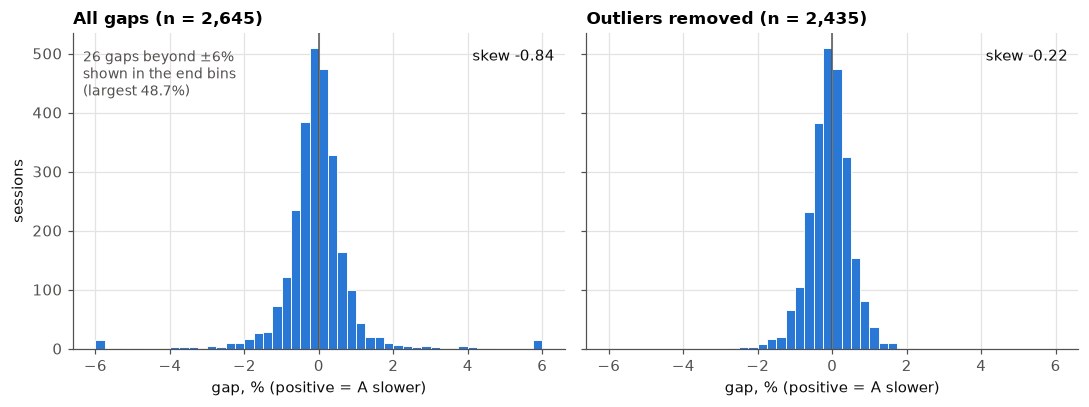

In [20]:
clean = gaps.loc[~gaps['outlier'], 'gap']
beyond = (gaps['gap'].abs() > LIM).sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
for ax, data, title in [(axes[0], gaps['gap'], f'All gaps (n = {len(gaps):,})'),
                        (axes[1], clean, f'Outliers removed (n = {len(clean):,})')]:
    ax.hist(data.clip(-LIM, LIM), bins=bins, color=BLUE, edgecolor='white', linewidth=0.6)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_title(title, loc='left')
    ax.set_xlabel('gap, % (positive = A slower)')
    ax.text(0.98, 0.95, f'skew {data.skew():.2f}', transform=ax.transAxes, ha='right', va='top', color=INK)
axes[0].set_ylabel('sessions')
axes[0].text(0.02, 0.95, f'{beyond} gaps beyond ±{LIM}%\nshown in the end bins\n(largest {gaps["gap"].abs().max():.1f}%)',
             transform=axes[0].transAxes, va='top', color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / 'gap_hist_all_vs_clean.png', bbox_inches='tight')
plt.show()


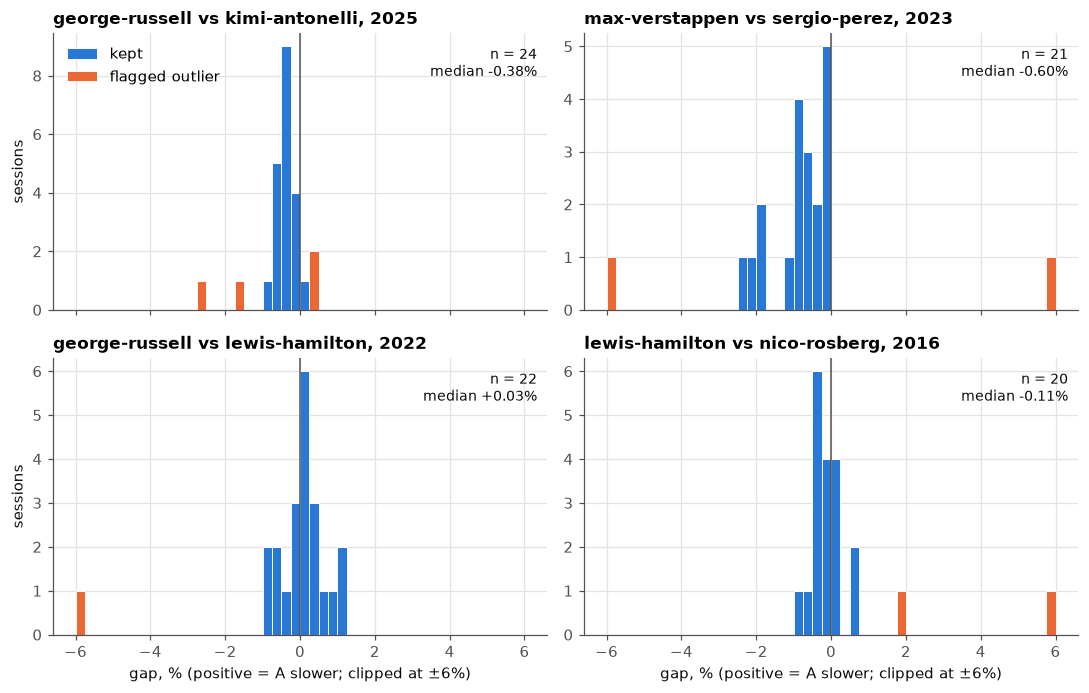

In [21]:
PAIRS = [('george-russell', 'kimi-antonelli', 2025), ('max-verstappen', 'sergio-perez', 2023),
         ('george-russell', 'lewis-hamilton', 2022), ('lewis-hamilton', 'nico-rosberg', 2016)]

fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True)
for ax, (a, b, yr) in zip(axes.flat, PAIRS):
    ps = gaps[(gaps['A'] == a) & (gaps['B'] == b) & (gaps['year'] == yr)]
    ax.hist([ps.loc[~ps['outlier'], 'gap'].clip(-LIM, LIM), ps.loc[ps['outlier'], 'gap'].clip(-LIM, LIM)],
            bins=bins, stacked=True, color=[BLUE, ORANGE], edgecolor='white', linewidth=0.6,
            label=['kept', 'flagged outlier'])
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_title(f'{a} vs {b}, {yr}', loc='left')
    ax.text(0.98, 0.95, f'n = {len(ps)}\nmedian {ps["gap"].median():+.2f}%', transform=ax.transAxes,
            ha='right', va='top', color=INK, fontsize=9)
for ax in axes[1]: ax.set_xlabel(f'gap, % (positive = A slower; clipped at ±{LIM}%)')
for ax in axes[:, 0]: ax.set_ylabel('sessions')
axes[0, 0].legend(loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'gap_hist_pairs.png', bbox_inches='tight')
plt.show()


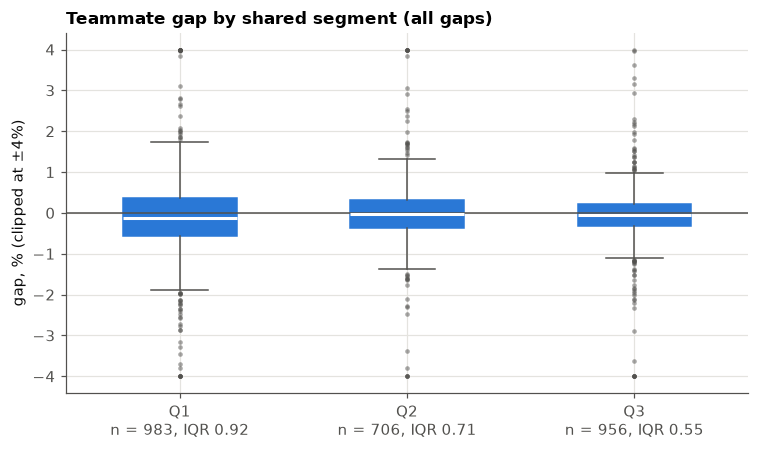

In [22]:
BLIM = 4                                             # y-axis limit for the boxplot, in %
order = ['Q1', 'Q2', 'Q3']
by_seg = [gaps.loc[gaps['segment'] == s, 'gap'] for s in order]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.boxplot([d.clip(-BLIM, BLIM) for d in by_seg], widths=0.5, patch_artist=True,
           boxprops={'facecolor': BLUE, 'edgecolor': BLUE},
           medianprops={'color': 'white', 'linewidth': 2}, whiskerprops={'color': MUTED},
           capprops={'color': MUTED},
           flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': MUTED, 'markeredgecolor': 'none', 'alpha': 0.5})
ax.set_xticks([1, 2, 3], [f'{s}\nn = {len(d)}, IQR {d.quantile(.75) - d.quantile(.25):.2f}' for s, d in zip(order, by_seg)])
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylabel(f'gap, % (clipped at ±{BLIM}%)')
ax.set_title('Teammate gap by shared segment (all gaps)', loc='left')
fig.tight_layout()
fig.savefig(FIG / 'gap_box_by_segment.png', bbox_inches='tight')
plt.show()


In [23]:
gaps.to_csv('data/teammate_gaps.csv', index=False)
print('saved', len(gaps), 'rows to teammate_gaps.csv with outlier and reason columns')


saved 2645 rows to teammate_gaps.csv with outlier and reason columns
